# Aula 08 — Prática · Refinamento visual e dashboard

Nesta aula: pegamos gráficos no estado bruto das aulas 04 e 06 e aplicamos as regras da teórica anterior — cinza mais uma cor de destaque, rótulo direto no lugar de legenda, menos tinta, título informativo. Fechamos com um esboço de dashboard montado só com `matplotlib`.

In [1]:
from pathlib import Path

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix

plt.rcParams.update({
    "figure.figsize": (10, 5.6),
    "figure.dpi": 110,
    "font.size": 13,
    "axes.grid": True, "grid.alpha": 0.3,
})

AZUL, LARANJA, CINZA = "#0173B2", "#DE8F05", "#949494"   # paleta "colorblind" do seaborn

# RAIZ = a pasta uma acima da pasta deste notebook: contém base_curada.csv, environment.yml
# e as pastas aula-XX. Encontrada subindo a partir do diretório de trabalho.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "base_curada.csv").is_file())
BASE = RAIZ / "base_curada.csv"
SAIDAS_A4 = Path("../aula-04/saidas")   # figuras já geradas na aula 04
SAIDAS_A6 = Path("../aula-06/saidas")   # figuras e scores já gerados na aula 06
SAIDAS = Path("saidas")                 # relativa à pasta do notebook; criada se não existir
SAIDAS.mkdir(parents=True, exist_ok=True)


def salvar(figura, nome):
    """Guarda a figura em disco. Não aparece na tela."""
    figura.savefig(SAIDAS / nome, dpi=600, bbox_inches="tight")


def mostrar_png(caminho, titulo):
    """Carrega um PNG já gerado numa aula anterior — o 'antes' nunca é replotado."""
    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    ax.imshow(mpimg.imread(caminho))
    ax.axis("off")
    ax.set_title(titulo)
    fig.tight_layout()
    return fig, ax

## A base, mais uma vez

In [2]:
dados = pd.read_csv(BASE)
dados[["cultura", "produtividade_t_ha"]].head(3)

,cultura,produtividade_t_ha
0,Milho,0.766080
1,Arroz,0.655809
2,Arroz,1.198024


In [3]:
dados.info()

<class 'pandas.DataFrame'>
RangeIndex: 3668 entries, 0 to 3667
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ano                      3668 non-null   int64  
 1   regiao                   3668 non-null   str    
 2   cultura                  3668 non-null   str    
 3   estacao                  3668 non-null   str    
 4   area_ha                  3668 non-null   float64
 5   producao_t               3668 non-null   int64  
 6   produtividade_t_ha       3668 non-null   float64
 7   produtividade_informada  3668 non-null   float64
 8   chuva_mm                 3668 non-null   float64
 9   fertilizante_kg_ha       3668 non-null   float64
 10  defensivo_kg_ha          3668 non-null   float64
dtypes: float64(6), int64(2), str(3)
memory usage: 315.3 KB


## As medianas que os dois "antes" tentam mostrar

In [4]:
# os números que os dois gráficos "antes" tentam comunicar de forma visual
dados.groupby("cultura")["produtividade_t_ha"].agg(["median", "count"]).sort_values("median")

,median,count
cultura,,
Feijão-moth,0.400000,107
Feijão-mungo,0.485783,722
Feijão-urad,0.540000,715
Milho,2.035275,953
Arroz,2.323973,1171


## O boxplot que a A04 deixou pronto

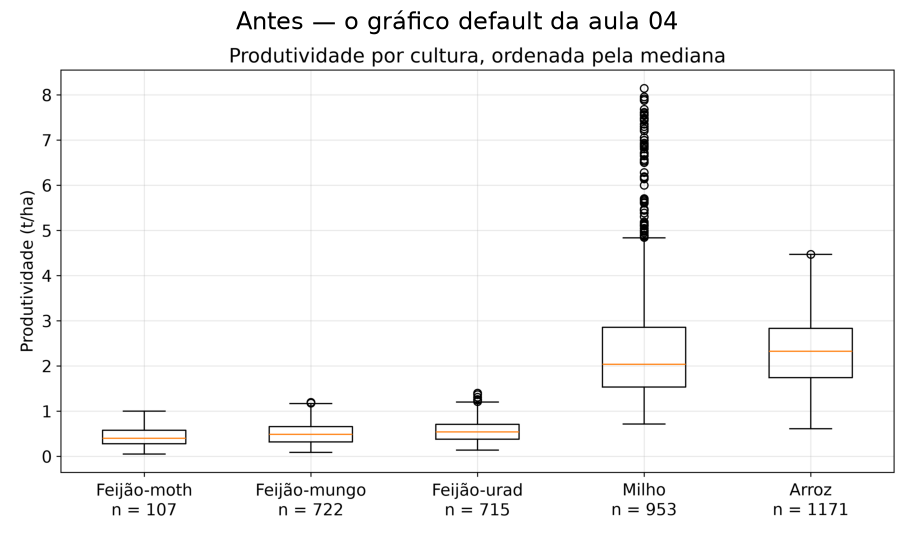

In [5]:
fig, ax = mostrar_png(SAIDAS_A4 / "f4-3-boxplot-cultura.png", "Antes — o gráfico default da aula 04")
salvar(fig, "f8-1-boxplot-cultura-antes.png")
plt.show()

## Cinza, destaque e rótulo direto

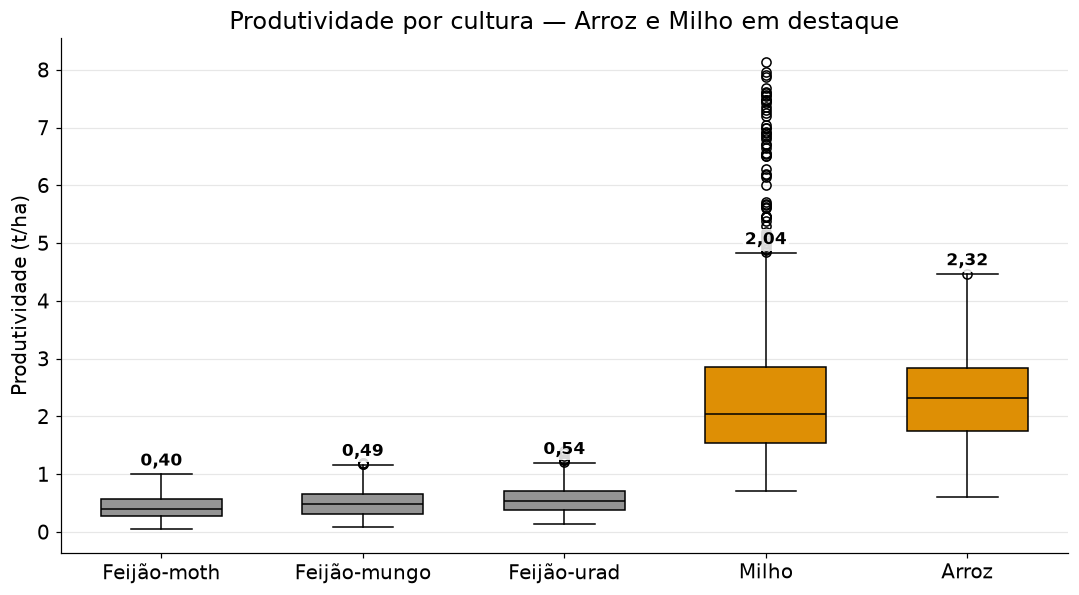

In [6]:
ALTO_PATAMAR = {"Arroz", "Milho"}   # achado da A04: dois patamares bem separados

medianas = dados.groupby("cultura")["produtividade_t_ha"].median().sort_values()
ordem = medianas.index.tolist()
grupos = [dados.loc[dados["cultura"] == cultura, "produtividade_t_ha"] for cultura in ordem]
cores = [LARANJA if cultura in ALTO_PATAMAR else CINZA for cultura in ordem]

fig, ax = plt.subplots()
caixas = ax.boxplot(grupos, tick_labels=ordem, patch_artist=True, widths=0.6,
                     medianprops={"color": "black"})
for caixa, cor in zip(caixas["boxes"], cores):
    caixa.set_facecolor(cor)

tampas = caixas["caps"]   # 2 por caixa (inferior, superior), na ordem dos grupos
# halo branco atrás do rótulo: Milho e Arroz têm nuvem densa de outliers logo acima do bigode,
# e o número precisa continuar legível por cima dela
for posicao, cultura in enumerate(ordem):
    topo = tampas[2 * posicao + 1].get_ydata()[0]
    ax.text(posicao + 1, topo + 0.15, f"{medianas.loc[cultura]:.2f}".replace(".", ","),
            ha="center", fontsize=11, fontweight="bold",
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5, "alpha": 0.85})

ax.set_ylabel("Produtividade (t/ha)")
ax.set_title("Produtividade por cultura — Arroz e Milho em destaque")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", visible=False)
fig.tight_layout()
salvar(fig, "f8-2-boxplot-cultura-depois.png")
plt.show()

## Antes e depois, na mesma escala

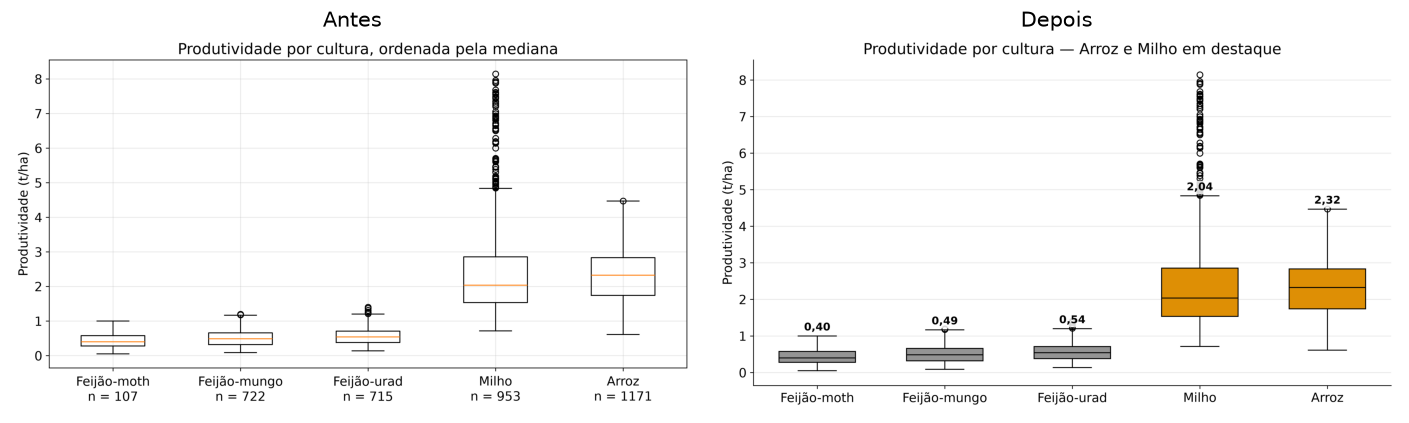

In [7]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.8))
for eixo, arquivo, rotulo in zip(
    eixos,
    [SAIDAS_A4 / "f4-3-boxplot-cultura.png", SAIDAS / "f8-2-boxplot-cultura-depois.png"],
    ["Antes", "Depois"],
):
    eixo.imshow(mpimg.imread(arquivo))
    eixo.axis("off")
    eixo.set_title(rotulo, fontsize=14)
fig.tight_layout()
salvar(fig, "f8-2b-boxplot-antes-depois.png")
plt.show()

## A importância inteira, sem hierarquia visual

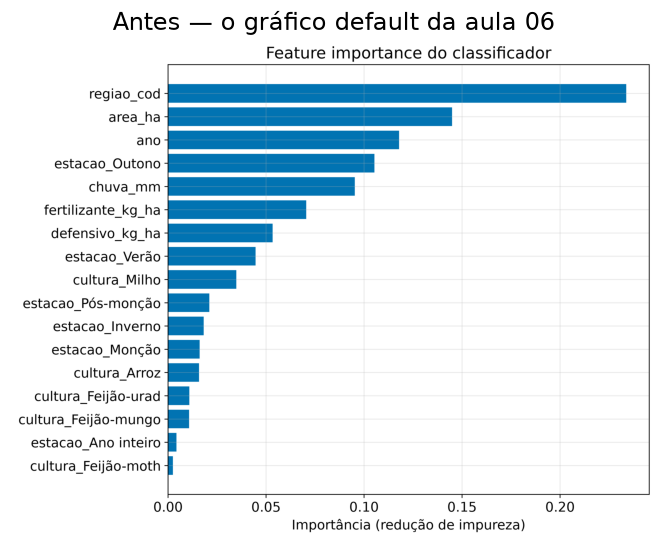

In [8]:
fig, ax = mostrar_png(SAIDAS_A6 / "f6-6-feature-importance.png", "Antes — o gráfico default da aula 06")
salvar(fig, "f8-3-feature-importance-antes.png")
plt.show()

## As seis que decidem o resto

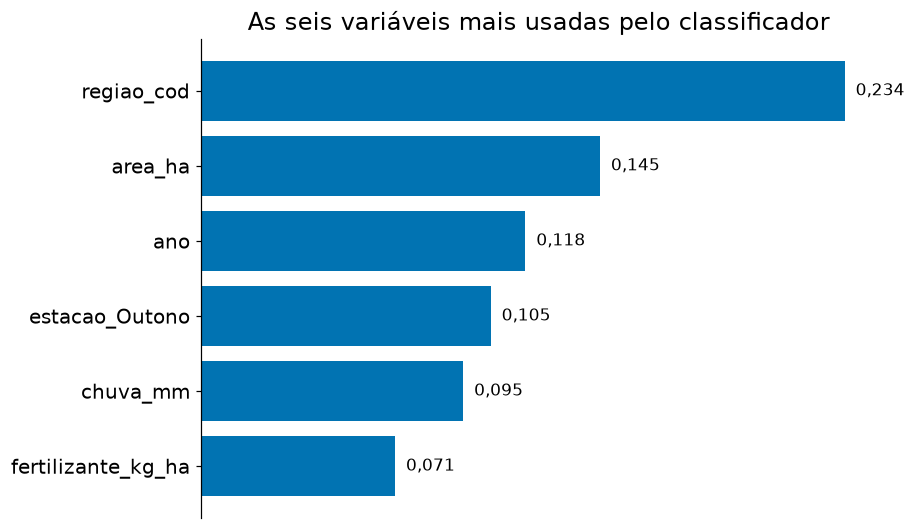

In [9]:
importancias = pd.read_csv(SAIDAS_A6 / "importancias.csv")
top6 = importancias.head(6).sort_values("importancia")   # crescente: a maior fica no topo do barh

fig, ax = plt.subplots(figsize=(8.5, 5))
barras = ax.barh(top6["feature"], top6["importancia"], color=AZUL)
for barra, valor in zip(barras, top6["importancia"]):
    ax.text(valor + 0.004, barra.get_y() + barra.get_height() / 2,
            f"{valor:.3f}".replace(".", ","), va="center", fontsize=11)

ax.set_title("As seis variáveis mais usadas pelo classificador")
ax.set_xticks([])
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.grid(False)
fig.tight_layout()
salvar(fig, "f8-4-feature-importance-depois.png")
plt.show()

## As seis, em número

In [10]:
ROTULOS = {
    "regiao_cod": "Região (código)", "area_ha": "Área plantada (ha)",
    "ano": "Ano da safra", "estacao_Outono": "Estação = Outono",
    "chuva_mm": "Chuva (mm)", "fertilizante_kg_ha": "Fertilizante (kg/ha)",
}
tabela_top6 = top6.sort_values("importancia", ascending=False).copy()
tabela_top6["feature"] = tabela_top6["feature"].map(ROTULOS)
tabela_top6.rename(columns={"feature": "variável", "importancia": "importância"}).round(3)

,variável,importância
0,Região (código),0.234
1,Área plantada (ha),0.145
2,Ano da safra,0.118
3,Estação = Outono,0.105
4,Chuva (mm),0.095
5,Fertilizante (kg/ha),0.071


## Três painéis, uma hierarquia


O dashboard alinha a prova do erro (matriz de confusão) com o argumento de decisão (feature importance). A matriz prova onde o modelo erra; a importância sugere por que ele decide assim, validando sua utilidade em nível de negócio (argumento vs. prova).

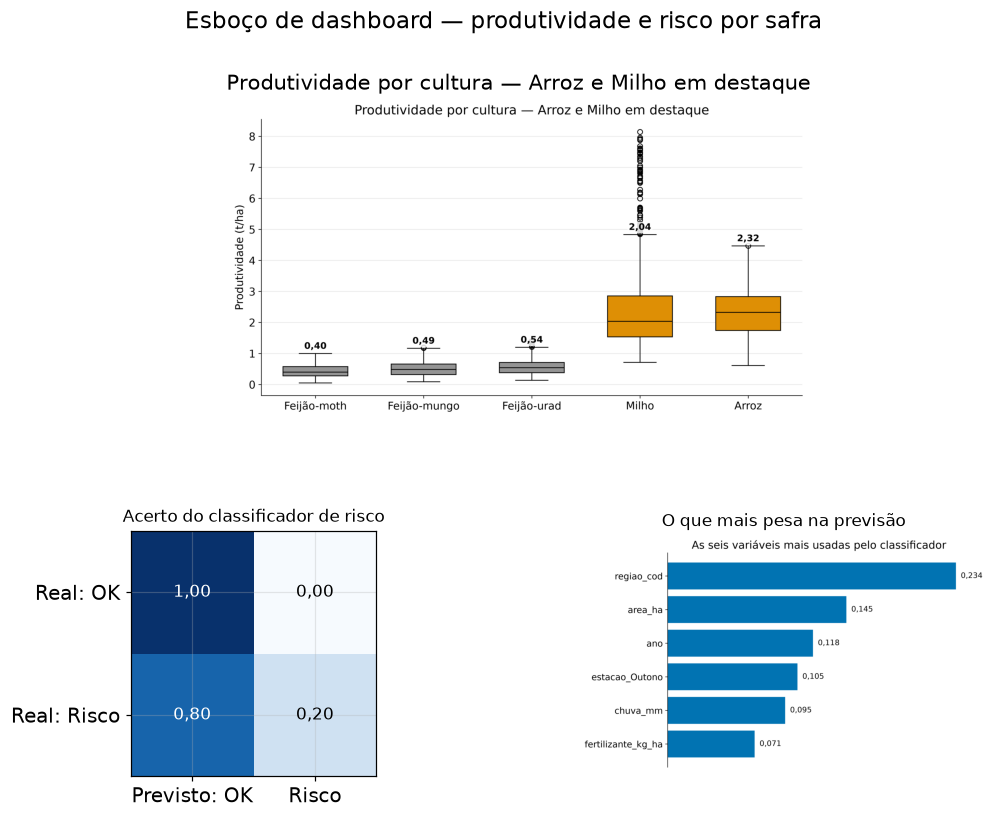

In [11]:
scores_teste = pd.read_csv(SAIDAS_A6 / "scores_teste.csv")
cm = confusion_matrix(scores_teste["real"], (scores_teste["score"] >= 0.5).astype(int))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig = plt.figure(figsize=(11, 8))
grade = fig.add_gridspec(2, 2, height_ratios=[1.3, 1], hspace=0.4, wspace=0.3)

# painel-mensagem: maior e primeiro, ocupando o topo inteiro
ax_msg = fig.add_subplot(grade[0, :])
ax_msg.imshow(mpimg.imread(SAIDAS / "f8-2-boxplot-cultura-depois.png"))
ax_msg.axis("off")
ax_msg.set_title("Produtividade por cultura — Arroz e Milho em destaque", fontsize=14)

# painéis de apoio, menores, na linha de baixo
ax_matriz = fig.add_subplot(grade[1, 0])
ax_matriz.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax_matriz.text(j, i, f"{cm_norm[i, j]:.2f}".replace(".", ","),
                        ha="center", va="center", fontsize=11,
                        color="white" if cm_norm[i, j] > 0.5 else "black")
ax_matriz.set_xticks([0, 1], ["Previsto: OK", "Risco"])
ax_matriz.set_yticks([0, 1], ["Real: OK", "Real: Risco"])
ax_matriz.set_title("Acerto do classificador de risco", fontsize=11)

ax_imp = fig.add_subplot(grade[1, 1])
ax_imp.imshow(mpimg.imread(SAIDAS / "f8-4-feature-importance-depois.png"))
ax_imp.axis("off")
ax_imp.set_title("O que mais pesa na previsão", fontsize=11)

fig.suptitle("Esboço de dashboard — produtividade e risco por safra", fontsize=15, y=0.98)
salvar(fig, "f8-5-esboco-dashboard.png")
plt.show()

## O que levamos daqui

Nenhum gráfico novo — só as regras da aula anterior aplicadas ao que já existia, e um esboço de como esses gráficos se juntam para quem decide. A próxima aula recorta o boxplot e a importância refinados aqui de novo, dessa vez com título-conclusão.